# Milestone 1: First API requests

In [165]:
# Milestone 1: fetch series info
import requests
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt
import os
os.makedirs("charts", exist_ok=True)

BASE_URL = "https://external-api.kalshi.com/trade-api/v2"
DOWNLOAD = False
FETCH_PRICES = False
SERIES = ["KXNFLGAME", "KXNBAGAME", "KXMLBGAME", "KXNHLGAME"]
NAMES = {
    "KXNFLGAME": "NFL",
    "KXNBAGAME": "NBA",
    "KXMLBGAME": "MLB", 
    "KXNHLGAME": "NHL"
    }

response = requests.get(BASE_URL + "/series/KXHIGHNY")
print(response.status_code)
data = response.json()
print(data["series"]["title"], "-", data["series"]["category"])

200
Highest temperature in NYC - Climate and Weather


In [57]:
# Milestone 1: fetch 5 settled markets
MARKET_URL = BASE_URL + "/markets"
markets_data = requests.get(MARKET_URL, params={"series_ticker": "KXHIGHNY", "status": "settled", "limit": 5}).json()

for market in markets_data["markets"]:
    print(f"{market['ticker']}: {market['title']} {market['result']}")

KXHIGHNY-26OCT14-T85: Will the maximum temperature be >85° on Oct 14, 2026? no
KXHIGHNY-26OCT14-T78: Will the maximum temperature be <78° on Oct 14, 2026? yes
KXHIGHNY-26OCT14-B84.5: Will the maximum temperature be 84-85° on Oct 14, 2026? no
KXHIGHNY-26OCT14-B82.5: Will the maximum temperature be 82-83° on Oct 14, 2026? no
KXHIGHNY-26OCT14-B80.5: Will the maximum temperature be 80-81° on Oct 14, 2026? no


# Milestone 2: find out what categories exist


## Choosing series

In [91]:
CATEGORIES_URL = BASE_URL + "/series"
categories = set()
series_data = requests.get(CATEGORIES_URL).json()
for s in series_data["series"]:
    categories.add(s["category"])
print(categories)


{'Culture', 'Mentions', 'Entertainment', 'World', 'Commodities', 'Business', 'Climate and Weather', 'Companies', 'Science and Technology', 'Education', 'Health', 'Economics', 'Exotics', 'Crypto', 'Politics', 'Elections', 'Sports', 'Transportation', 'Social', 'Financials'}


In [83]:
def top_series(category, n=15):
    print(f"Top {n} {category} Series by Volume")
    category_data = requests.get(CATEGORIES_URL, params={"category": category, "include_volume": True}).json()
    print(len(category_data["series"]))
    top = sorted(category_data["series"], key=lambda s: float(s["volume_fp"]), reverse=True)

    for series in top[:n]:
        print(series["ticker"], series["title"], series["volume_fp"])

top_series("Climate and Weather")
top_series("Elections")
top_series("Financials")


Top 15 Climate and Weather Series by Volume
424
KXHIGHLAX Highest temperature in Los Angeles 181324599.00
KXHIGHNY Highest temperature in NYC 149074568.00
KXHIGHCHI Highest temperature in Chicago 113029241.00
KXHIGHMIA Highest temperature in Miami 103517882.00
KXHIGHAUS Highest temperature in Austin 78821467.00
KXRAIN Where will it rain daily 58925371.00
KXHIGHDEN Highest temperature in Denver 52047958.00
KXHIGHPHIL Highest temperature in Philadelphia 42774183.00
KXRAINNYC NYC rain 30548636.00
KXHIGHTSFO San Francisco High Temperature Daily 19735017.00
KXHIGHTPHX Phoenix High Temperature Daily 18780801.00
KXHIGHTSEA Seattle Maximum Temperature Daily 17648558.00
KXHIGHTATL Atlanta Max Temperature 17561814.00
KXHIGHTBOS Boston Maximum Daily Temperature 16635889.00
KXTEMPMIAH Hourly Directional Miami Temperature 16021015.00
Top 15 Elections Series by Volume
2304
PRES Presidential elections 535948943.00
KXPRESNOMD Democratic Primary winner 239431072.00
POPVOTEMOV Popular vote margin of vic

In [84]:
def check_lifetime(series_ticker):
    print(f"5 Settled Markets from {series_ticker}")
    settled_markets = requests.get(MARKET_URL, params={"series_ticker": series_ticker, "status": "settled", "limit": 5}).json()
    for market in settled_markets["markets"]:
        diff = pd.to_datetime(market["close_time"]) - pd.to_datetime(market["open_time"])
        print(market["ticker"], diff)

check_lifetime("KXNBAGAME")
check_lifetime("KXNFLGAME")
check_lifetime("KXNHLGAME")
check_lifetime("KXMLBGAME")

5 Settled Markets from KXNBAGAME
KXNBAGAME-26OCT12LIOPOR-POR 0 days 21:55:11
KXNBAGAME-26OCT12LIOPOR-LIO 0 days 21:55:11
KXNBAGAME-26OCT14DENLAC-LAC 7 days 02:20:50.185091
KXNBAGAME-26OCT14DENLAC-DEN 7 days 02:20:50.185091
KXNBAGAME-26OCT14PHXSAS-SAS 7 days 02:27:31.962811
5 Settled Markets from KXNFLGAME
KXNFLGAME-26OCT12BUFLAR-LAR 13 days 23:42:50
KXNFLGAME-26OCT12BUFLAR-BUF 13 days 23:42:50
KXNFLGAME-26OCT11BALATL-BAL 12 days 23:42:15
KXNFLGAME-26OCT11BALATL-ATL 12 days 23:42:15
KXNFLGAME-26OCT11CHIGB-GB 12 days 16:02:30
5 Settled Markets from KXNHLGAME
KXNHLGAME-26OCT14DALCOL-DAL 7 days 02:19:35
KXNHLGAME-26OCT14DALCOL-COL 7 days 02:19:35
KXNHLGAME-26OCT14MTLWSH-WSH 7 days 01:19:58
KXNHLGAME-26OCT14MTLWSH-MTL 7 days 01:19:58
KXNHLGAME-26OCT13BOSSJ-SJ 7 days 01:43:54
5 Settled Markets from KXMLBGAME
KXMLBGAME-26OCT132000CLETB-TB 2 days 23:30:21
KXMLBGAME-26OCT132000CLETB-CLE 2 days 23:30:21
KXMLBGAME-26OCT122000CLETB-TB 1 days 23:44:51
KXMLBGAME-26OCT122000CLETB-CLE 1 days 23:44:51


## Downloading

In [85]:
#Used to find cutoff date for historical vs live markets
cutoff = requests.get(BASE_URL + "/historical/cutoff").json()
CUTOFF = cutoff["market_settled_ts"]
print(cutoff)

{'market_positions_last_updated_ts': '2026-08-16T00:00:00Z', 'market_settled_ts': '2026-08-16T00:00:00Z', 'orders_updated_ts': '2026-10-01T00:00:00Z', 'trades_created_ts': '2026-08-16T00:00:00Z'}


In [86]:
def get_settled_markets(series_ticker, url):
    all_markets = []
    cursor = None
    while True:
        params = {"series_ticker": series_ticker, "limit": 1000}
        if url == MARKET_URL:
            params["status"] = "settled"
        if cursor:
            params["cursor"] = cursor
        data = requests.get(url, params=params).json()
        all_markets.extend(data["markets"])
        cursor = data["cursor"]
        if not cursor:
            break
        time.sleep(0.2)
    return all_markets

HIST_URL = BASE_URL + "/historical/markets"
nfl_live = get_settled_markets("KXNFLGAME", MARKET_URL)
nfl_hist = get_settled_markets("KXNFLGAME", HIST_URL)
print(len(nfl_live))
print(len(nfl_hist))

254
696


In [ ]:
if DOWNLOAD:
    all_markets = []
    for ticker in SERIES:
        combined = get_settled_markets(ticker, MARKET_URL) + get_settled_markets(ticker, HIST_URL)
        for market in combined:
            market["series"] = ticker
        all_markets.extend(combined)
        print(ticker, len(combined))

    print(len(all_markets))

In [88]:
if DOWNLOAD:
    df = pd.DataFrame(all_markets)
    df.to_csv("markets.csv", index=False)
    print(df.shape)
    print(df["series"].value_counts())
    print(df["ticker"].duplicated().sum())

In [89]:
#Checking which series have dupes
if DOWNLOAD:
    dupes = df[df["ticker"].duplicated(keep=False)]
    print(len(dupes))
    print(dupes["series"].value_counts())

In [90]:
#Dropping dupes
if DOWNLOAD:
    df = df.drop_duplicates(subset="ticker")
    print(df.shape)
    print(df["ticker"].duplicated().sum())
    df.to_csv("markets.csv", index=False)

# Milestone 3: Clean the data

In [67]:
df = pd.read_csv("markets.csv", low_memory=False)
print(df.shape)

(16688, 46)


In [68]:
#See types
df.dtypes

can_close_early                bool
close_time                      str
created_time                    str
custom_strike                   str
early_close_condition           str
event_ticker                    str
exchange_index                int64
expected_expiration_time        str
expiration_time                 str
expiration_value                str
last_price_dollars          float64
latest_expiration_time          str
market_type                     str
no_ask_dollars              float64
no_bid_dollars              float64
no_sub_title                    str
notional_value_dollars      float64
occurrence_datetime             str
open_interest_fp            float64
open_time                       str
previous_price_dollars      float64
previous_yes_ask_dollars    float64
previous_yes_bid_dollars    float64
price_level_structure           str
price_ranges                    str
result                          str
rules_primary                   str
rules_secondary             

In [69]:
#Clean result column
df = df[df["result"].isin(["yes", "no"])]
print(df.shape)

(16644, 46)


In [70]:
#Clean times
df["close_time"] = pd.to_datetime(df["close_time"], format="ISO8601")
df["open_time"] = pd.to_datetime(df["open_time"], format="ISO8601")

df.dtypes

can_close_early                            bool
close_time                  datetime64[us, UTC]
created_time                                str
custom_strike                               str
early_close_condition                       str
event_ticker                                str
exchange_index                            int64
expected_expiration_time                    str
expiration_time                             str
expiration_value                            str
last_price_dollars                      float64
latest_expiration_time                      str
market_type                                 str
no_ask_dollars                          float64
no_bid_dollars                          float64
no_sub_title                                str
notional_value_dollars                  float64
occurrence_datetime                         str
open_interest_fp                        float64
open_time                   datetime64[us, UTC]
previous_price_dollars                  

In [71]:
#Adding an outcome column
df["outcome"] = (df["result"] == "yes").astype(int)
df["outcome"].mean()

np.float64(0.49975967315549147)

In [72]:
#Clean volume
df = df[df["volume_fp"] > 0]
df.shape

(16631, 47)

In [73]:
df["event_ticker"].value_counts().value_counts()

count
2    8315
1       1
Name: count, dtype: int64

In [74]:
#Shuffle rows
df = df.sample(frac=1, random_state=42).drop_duplicates(subset="event_ticker")
print(df.shape)
print(df["outcome"].mean())

(8316, 47)
0.5018037518037518


## Market lifetimes

In [77]:
df["lifetime_hours"] = (df["close_time"] - df["open_time"]).dt.total_seconds() / 3600
print(df["lifetime_hours"].head())

df.groupby("series")["lifetime_hours"].describe()

4532     74.324444
13836    73.571944
12432     8.639514
9569     14.052059
4826     74.244444
Name: lifetime_hours, dtype: float64


,count,mean,std,min,25%,50%,75%,max
series,,,,,,,,
KXMLBGAME,4669.0,60.185110,321.889507,3.407914,14.065171,74.087500,74.657222,8165.593611
KXNBAGAME,1494.0,63.876301,28.834693,11.193531,57.152254,58.661776,59.734322,270.805833
KXNFLGAME,452.0,536.461266,704.264456,73.603624,225.330945,292.375144,315.571792,2938.188611
KXNHLGAME,1701.0,76.494451,29.614333,17.243503,67.988736,69.065031,73.241944,262.850833


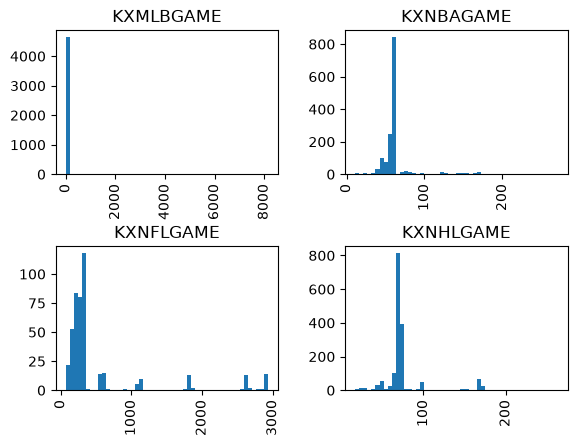

In [78]:
df.hist(column="lifetime_hours", by="series", bins=50)
plt.show()

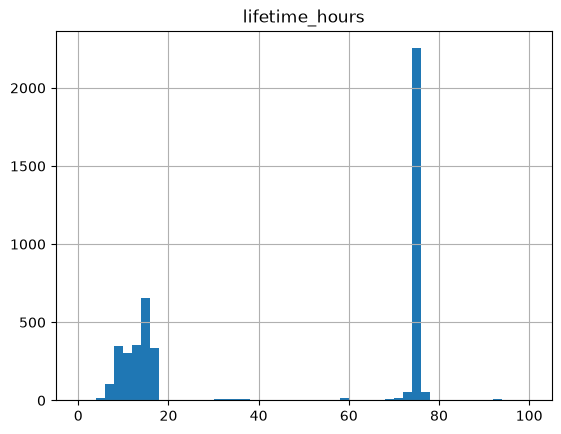

In [79]:
mlb = df[df["series"] == "KXMLBGAME"]
mlb.hist(column="lifetime_hours", bins=50, range=(0, 100))
plt.show()

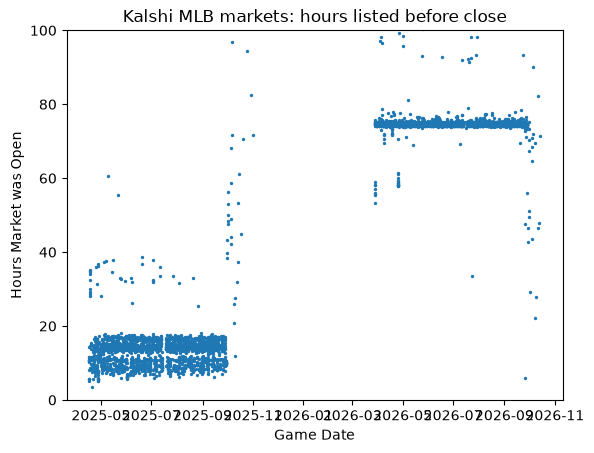

In [80]:
plt.scatter(mlb["close_time"], mlb["lifetime_hours"], s=2)
plt.ylim(0, 100)
plt.title("Kalshi MLB markets: hours listed before close")
plt.xlabel("Game Date")
plt.ylabel("Hours Market was Open")
plt.savefig("charts/mlb_listing_change.png")
plt.show()

In [95]:
#24 hour filter
df = df[df["lifetime_hours"] >= 24]
print(df.shape)
print(df["series"].value_counts())

(6166, 48)
series
KXMLBGAME    2543
KXNHLGAME    1692
KXNBAGAME    1479
KXNFLGAME     452
Name: count, dtype: int64


# Milestone 4

In [ ]:
#scratch cell
row = df.iloc[0]
print(row["ticker"], row["series"], row["close_time"])

close_ts = int(row["close_time"].timestamp())
start_ts = close_ts - 48 * 3600

if row["close_time"] < pd.to_datetime(CUTOFF):
    url = BASE_URL + f"/historical/markets/{row['ticker']}/candlesticks"
else:
    url = BASE_URL + f"/series/{row['series']}/markets/{row['ticker']}/candlesticks"

candle_data = requests.get(url, params={"start_ts": start_ts, "end_ts": close_ts, "period_interval": 60}).json()

print(len(candle_data["candlesticks"]))
print(candle_data["candlesticks"][0])

KXMLBGAME-26SEP061610ATHSEA-SEA KXMLBGAME 2026-09-06 22:44:28+00:00
44
{'end_period_ts': 1788562800, 'open_interest_fp': '21.00', 'price': {'previous_dollars': '0.6600'}, 'volume_fp': '0.00', 'yes_ask': {'close_dollars': '0.6700', 'high_dollars': '0.6700', 'low_dollars': '0.6400', 'open_dollars': '0.6600'}, 'yes_bid': {'close_dollars': '0.6600', 'high_dollars': '0.6600', 'low_dollars': '0.6300', 'open_dollars': '0.6300'}}


In [103]:
def get_close(d):
    if d.get("close") is None:
        return d.get("close_dollars")
    return d.get("close")

In [120]:
def get_price_24h(row):
    close_ts = int(row["close_time"].timestamp())
    target_ts = close_ts - 24 *3600
    start_ts = target_ts -3 * 3600
    end_ts = target_ts + 3 * 3600
    if row["close_time"] < pd.to_datetime(CUTOFF):
        url = BASE_URL + f"/historical/markets/{row['ticker']}/candlesticks"
    else:
        url = BASE_URL + f"/series/{row['series']}/markets/{row['ticker']}/candlesticks"
    
    for attempt in range(5):
        response = requests.get(url, params={"start_ts": start_ts, "end_ts": end_ts, "period_interval": 60})        
        if response.status_code == 429:      # "too many requests"
            time.sleep(2 ** attempt)          # wait 1, 2, 4, 8, 16 seconds
            continue
        break
    candle_data = response.json()    
    
    candles = candle_data["candlesticks"]    
    if not candles:
        return None
    closest = min(candles, key=lambda c: abs(c["end_period_ts"] - target_ts))

    price = get_close(closest["price"])

    if price is None:
        bid = get_close(closest["yes_bid"])
        ask = get_close(closest["yes_ask"])
        price = (float(bid) + float(ask)) / 2
    return float(price)


In [ ]:
#Test get_price_24h
for i in range(5):
    print(df.iloc[i]["series"], df.iloc[i]["ticker"], get_price_24h(df.iloc[i]))

KXMLBGAME KXMLBGAME-26SEP061610ATHSEA-SEA 0.65
KXNHLGAME KXNHLGAME-26APR12OTTNJ-OTT 0.55
KXMLBGAME KXMLBGAME-26AUG262105MINATH-MIN 0.57
KXNHLGAME KXNHLGAME-25DEC15ANANYR-NYR 0.54
KXNBAGAME KXNBAGAME-25DEC07PORMEM-POR 0.47


In [ ]:
#Collect all data
if FETCH_PRICES:
    prices = []
    for i in range(len(df)):
        row = df.iloc[i]
        try:
            price = get_price_24h(row)
        except Exception:
            price = None
        prices.append(price)
        if (i + 1) % 50 == 0:
            print(i + 1, len(prices))

50 50
100 100
150 150
200 200
250 250
300 300
350 350
400 400
450 450
500 500
550 550
600 600
650 650
700 700
750 750
800 800
850 850
900 900
950 950
1000 1000
1050 1050
1100 1100
1150 1150
1200 1200
1250 1250
1300 1300
1350 1350
1400 1400
1450 1450
1500 1500
1550 1550
1600 1600
1650 1650
1700 1700
1750 1750
1800 1800
1850 1850
1900 1900
1950 1950
2000 2000
2050 2050
2100 2100
2150 2150
2200 2200
2250 2250
2300 2300
2350 2350
2400 2400
2450 2450
2500 2500
2550 2550
2600 2600
2650 2650
2700 2700
2750 2750
2800 2800
2850 2850
2900 2900
2950 2950
3000 3000
3050 3050
3100 3100
3150 3150
3200 3200
3250 3250
3300 3300
3350 3350
3400 3400
3450 3450
3500 3500
3550 3550
3600 3600
3650 3650
3700 3700
3750 3750
3800 3800
3850 3850
3900 3900
3950 3950
4000 4000
4050 4050
4100 4100
4150 4150
4200 4200
4250 4250
4300 4300
4350 4350
4400 4400
4450 4450
4500 4500
4550 4550
4600 4600
4650 4650
4700 4700
4750 4750
4800 4800
4850 4850
4900 4900
4950 4950
5000 5000
5050 5050
5100 5100
5150 5150
5200 5200


In [ ]:
if FETCH_PRICES:
    df["price_24h"] = prices
    df.to_csv("clean_markets.csv", index=False)

In [ ]:
if FETCH_PRICES:
    print(df["price_24h"].isna().mean())
    print(df["price_24h"].describe())
    print(df["price_24h"].nunique())

0.0017839766461239053
count    6155.000000
mean        0.504516
std         0.139994
min         0.040000
25%         0.430000
50%         0.500000
75%         0.580000
max         0.950000
Name: price_24h, dtype: float64
152


In [ ]:
if FETCH_PRICES:
    df["is_hist"] = df["close_time"] < pd.to_datetime(CUTOFF)
    print(df.groupby("series")["price_24h"].apply(lambda s: s.isna().mean()))
    print(df.groupby("is_hist")["price_24h"].apply(lambda s: s.isna().mean()))

series
KXMLBGAME    0.0
KXNBAGAME    0.0
KXNFLGAME    0.0
KXNHLGAME    0.0
Name: price_24h, dtype: float64
is_hist
False    0.0
True     0.0
Name: price_24h, dtype: float64


In [ ]:
if FETCH_PRICES:
    missing = df[df["price_24h"].isna()]
    row = missing.iloc[0]
    print(row["ticker"], row["close_time"])
    get_price_24h(row)

KXNBAGAME-26MAR31NYKHOU-NYK 2026-04-01 02:30:53+00:00


0.52

In [ ]:
if FETCH_PRICES:
    missing_idx = df.index[df["price_24h"].isna()]
    print(len(missing_idx))

3851


In [ ]:
if FETCH_PRICES:
    for n, idx in enumerate(missing_idx):
        row = df.loc[idx]
        try:
            price = get_price_24h(row)
        except Exception:
            price = None
        df.loc[idx, "price_24h"] = price
        time.sleep(0.25)
        if (n + 1) % 500 == 0: 
            print(n + 1)

500
1000
1500
2000
2500
3000
3500


In [ ]:
if FETCH_PRICES:
    df = df[df["price_24h"].notna()]
    df.to_csv("clean_markets.csv", index=False)

# Milestone 5: Brier scores

In [126]:
df = pd.read_csv("clean_markets.csv", low_memory=False)
df["close_time"] = pd.to_datetime(df["close_time"], format="ISO8601")
print(df.shape)
print(df["price_24h"].isna().sum())

(6155, 50)
0


In [133]:
def brier(prices, outcomes):
    return ((prices - outcomes) ** 2).mean()

brier(pd.Series([0.5, 0.5]), pd.Series([1, 0]))

np.float64(0.25)

In [134]:
print(brier(df["price_24h"], df["outcome"]))
print(df.groupby("series").apply(lambda g: brier(g["price_24h"], g["outcome"])))
print(brier(df["last_price_dollars"], df["outcome"]))

0.23287699837530462
series
KXMLBGAME    0.243977
KXNBAGAME    0.204548
KXNFLGAME    0.225466
KXNHLGAME    0.243008
dtype: float64
0.000775889520714866


# Milestone 6

In [136]:
df["bin"] = pd.cut(df["price_24h"], bins=[0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
print(df["bin"].value_counts().sort_index())

bin
(0.0, 0.1]      33
(0.1, 0.2]     137
(0.2, 0.3]     245
(0.3, 0.4]     801
(0.4, 0.5]    1897
(0.5, 0.6]    1837
(0.6, 0.7]     742
(0.7, 0.8]     287
(0.8, 0.9]     144
(0.9, 1.0]      32
Name: count, dtype: int64


In [143]:
calib = df.groupby("bin", observed=True).agg(
    avg_price=("price_24h", "mean"),
    win_rate=("outcome", "mean"),
    count=("outcome", "size"),
)
print(calib)

            avg_price  win_rate  count
bin                                   
(0.0, 0.1]   0.082727  0.000000     33
(0.1, 0.2]   0.153212  0.145985    137
(0.2, 0.3]   0.260510  0.289796    245
(0.3, 0.4]   0.364981  0.368290    801
(0.4, 0.5]   0.457161  0.477069   1897
(0.5, 0.6]   0.551263  0.535656   1837
(0.6, 0.7]   0.645398  0.615903    742
(0.7, 0.8]   0.746829  0.766551    287
(0.8, 0.9]   0.852361  0.812500    144
(0.9, 1.0]   0.922813  0.968750     32


In [146]:
calib["se"] = (calib["avg_price"] * (1 - calib["avg_price"]) / calib["count"]) ** 0.5

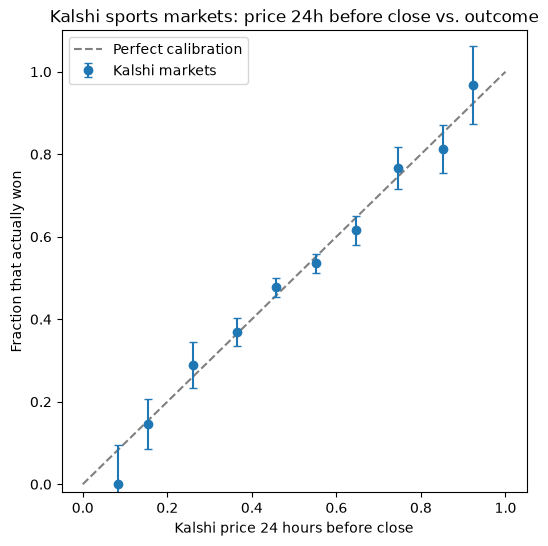

In [149]:
plt.figure(figsize=(6, 6))

plt.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
plt.errorbar(
    calib["avg_price"],
    calib["win_rate"],
    yerr=2 * calib["se"],
    fmt="o",
    capsize=3,
    label="Kalshi markets",
)
plt.ylim(-0.02, 1.1)
plt.title("Kalshi sports markets: price 24h before close vs. outcome")
plt.xlabel("Kalshi price 24 hours before close")
plt.ylabel("Fraction that actually won")
plt.legend()

plt.savefig("charts/calibration.png", dpi=150, bbox_inches="tight")
plt.show()

# Milestone 7: Calibration by league

In [156]:
def make_calib(data):
    calib = data.groupby("bin", observed=True).agg(
        avg_price=("price_24h", "mean"),
        win_rate=("outcome", "mean"),
        count=("outcome", "size"),
    )
    calib["se"] = (calib["avg_price"] * (1 - calib["avg_price"]) / calib["count"]) ** 0.5
    calib = calib[calib["count"] >= 20]
    return calib

In [161]:
make_calib(df)

,avg_price,win_rate,count,se
bin,,,,
"(0.0, 0.1]",0.082727,0.000000,33,0.047953
"(0.1, 0.2]",0.153212,0.145985,137,0.030773
"(0.2, 0.3]",0.260510,0.289796,245,0.028041
"(0.3, 0.4]",0.364981,0.368290,801,0.017010
"(0.4, 0.5]",0.457161,0.477069,1897,0.011438
"(0.5, 0.6]",0.551263,0.535656,1837,0.011604
"(0.6, 0.7]",0.645398,0.615903,742,0.017562
"(0.7, 0.8]",0.746829,0.766551,287,0.025667
"(0.8, 0.9]",0.852361,0.812500,144,0.029562


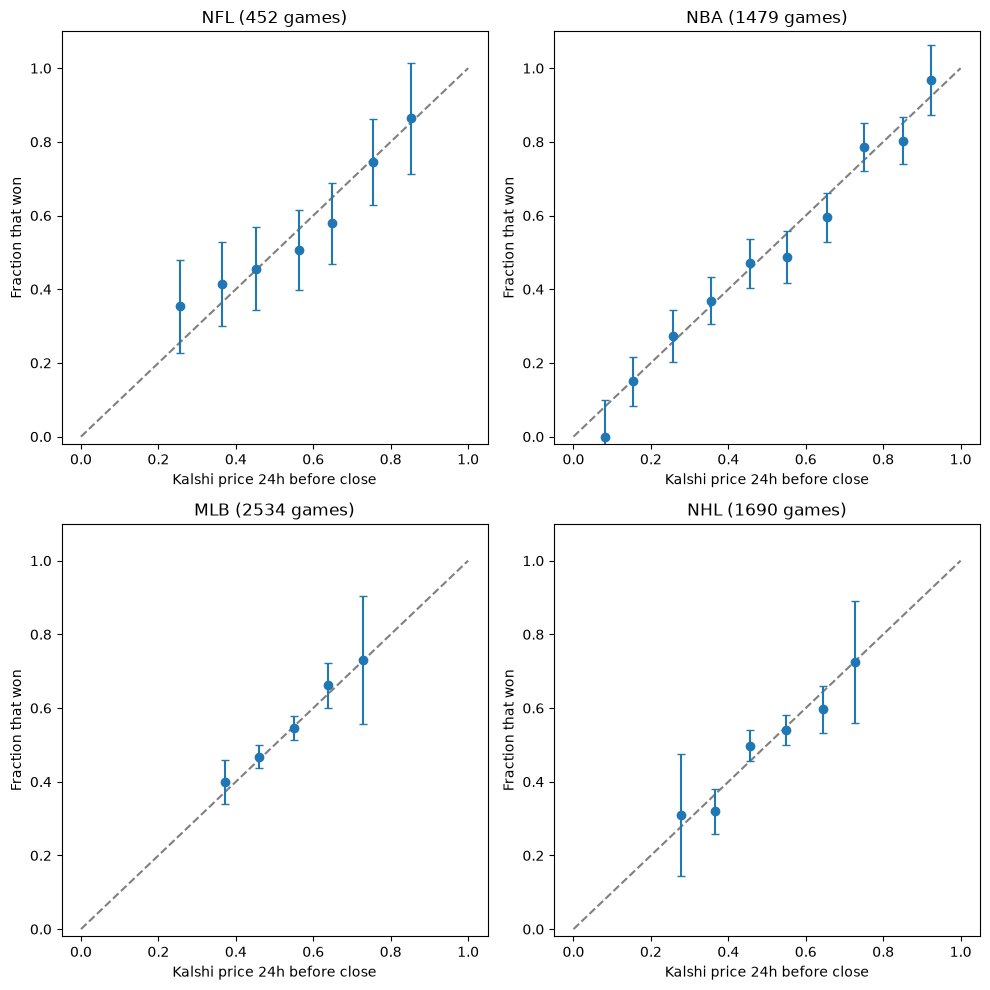

In [173]:
#Loop over each league
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for ax, league in zip(axes.flat, SERIES):
    sub = df[df["series"] == league]
    c = make_calib(sub)
    ax.plot([0, 1], [0, 1], "--", color="gray")
    ax.errorbar(
        c["avg_price"], c["win_rate"],
        yerr=2 * c["se"],
        fmt="o", capsize=3,
    )
    ax.set_title(f"{NAMES[league]} ({len(sub)} games)")
    ax.set_xlabel("Kalshi price 24h before close")
    ax.set_ylabel("Fraction that won")
    ax.set_ylim(-0.02, 1.1)

plt.tight_layout()
plt.savefig("charts/calibration_by_league.png", dpi=150, bbox_inches="tight")
plt.show()

In [164]:
print(df.groupby("series")["price_24h"].std())

series
KXMLBGAME    0.082722
KXNBAGAME    0.220700
KXNFLGAME    0.184605
KXNHLGAME    0.096791
Name: price_24h, dtype: float64


In [170]:
#Calibration error
df["vol_q"] = pd.qcut(df["volume_fp"], 4, labels=["Low", "Mid-low", "Mid-high", "High"])

def calib_error(data):
    c = make_calib(data)
    gaps = (c["avg_price"] - c["win_rate"]).abs()
    return np.average(gaps, weights=c["count"])

print(df.groupby("vol_q", observed=True).apply(calib_error))

vol_q
Low         0.044555
Mid-low     0.023695
Mid-high    0.028531
High        0.080440
dtype: float64


In [171]:
print(make_calib(df[df["vol_q"] == "High"]))

            avg_price  win_rate  count        se
bin                                             
(0.1, 0.2]   0.154839  0.290323     62  0.045942
(0.2, 0.3]   0.254911  0.383929    112  0.041180
(0.3, 0.4]   0.361800  0.450000    200  0.033978
(0.4, 0.5]   0.458359  0.468085    329  0.027470
(0.5, 0.6]   0.554688  0.473815    401  0.024819
(0.6, 0.7]   0.645678  0.525424    236  0.031135
(0.7, 0.8]   0.747500  0.695312    128  0.038400
(0.8, 0.9]   0.846607  0.642857     56  0.048156


In [172]:
   print(df.groupby("vol_q", observed=True)["series"].value_counts(normalize=True))

vol_q     series   
Low       KXNHLGAME    0.800520
          KXMLBGAME    0.096166
          KXNBAGAME    0.073424
          KXNFLGAME    0.029890
Mid-low   KXMLBGAME    0.584146
          KXNHLGAME    0.236517
          KXNBAGAME    0.166992
          KXNFLGAME    0.012346
Mid-high  KXMLBGAME    0.634590
          KXNBAGAME    0.279584
          KXNHLGAME    0.043563
          KXNFLGAME    0.042263
High      KXNBAGAME    0.441196
          KXMLBGAME    0.332034
          KXNFLGAME    0.209227
          KXNHLGAME    0.017544
Name: proportion, dtype: float64
